In [1]:
import pandas as pd 
df=pd.read_excel('data-analyst-task-datasets.xlsx',sheet_name=None)
print(df['customers'].isna().sum())
print(df['payments'].isna().sum())
print(df['claims'].isna().sum())
df['policies']['broker_name']=df['policies']['broker_name'].fillna('Unknown')
#print(df['policies']['broker_name'])
pd.set_option('display.max_rows',None)
print(df['policies'])



customer_id    0
full_name      0
gender         0
birth_date     0
region         0
join_date      0
dtype: int64
payment_id        0
policy_id         0
payment_date      0
payment_amount    0
payment_method    0
is_overdue        0
dtype: int64
claim_id           0
policy_id          0
claim_date         0
claim_amount       0
approved_amount    0
claim_status       0
claim_reason       0
dtype: int64
      policy_id  customer_id insurance_type start_date   end_date  \
0         10001          318       Property 2023-09-03 2024-07-22   
1         10002          843       Property 2022-01-26 2023-04-18   
2         10003           36       Property 2024-07-10 2025-02-07   
3         10004          447          Motor 2023-09-15 2025-01-31   
4         10005          801        Medical 2024-11-22 2025-11-22   
5         10006          953       Property 2024-04-26 2025-05-26   
6         10007          252        Medical 2024-12-13 2025-08-18   
7         10008          651          Mo

In [2]:
print(df['customers']['customer_id'].duplicated().sum())
print(df['claims'].duplicated().sum())
print(df['payments'].duplicated().sum())
print(df['policies'].duplicated().sum())


0
0
0
0


In [70]:
print(df['claims'].dtypes)
print(df['payments'].dtypes)
print(df['policies'].dtypes)
print(df['customers'].dtypes)


claim_id                    int64
policy_id                   int64
claim_date         datetime64[ns]
claim_amount              float64
approved_amount           float64
claim_status               object
claim_reason               object
dtype: object
payment_id                 int64
policy_id                  int64
payment_date      datetime64[ns]
payment_amount           float64
payment_method            object
is_overdue                 int64
dtype: object
policy_id                  int64
customer_id                int64
insurance_type            object
start_date        datetime64[ns]
end_date          datetime64[ns]
premium_amount           float64
channel                   object
status                    object
broker_name               object
dtype: object
customer_id             int64
full_name              object
gender                 object
birth_date     datetime64[ns]
region                 object
join_date      datetime64[ns]
dtype: object


In [54]:
#2-ci
print(df['claims'].columns)
print(df['payments'].columns)
print(df['policies'].columns)
print(df['customers'].columns)

Index(['claim_id', 'policy_id', 'claim_date', 'claim_amount',
       'approved_amount', 'claim_status', 'claim_reason'],
      dtype='object')
Index(['payment_id', 'policy_id', 'payment_date', 'payment_amount',
       'payment_method', 'is_overdue'],
      dtype='object')
Index(['policy_id', 'customer_id', 'insurance_type', 'start_date', 'end_date',
       'premium_amount', 'channel', 'status', 'broker_name'],
      dtype='object')
Index(['customer_id', 'full_name', 'gender', 'birth_date', 'region',
       'join_date'],
      dtype='object')


In [2]:
mergeddf=pd.merge(df['customers'],df['policies'],on='customer_id',how='left')
mergeddf=mergeddf.merge(df['claims'],on='policy_id',how='left')
mergeddf=mergeddf.merge(df['payments'],on='policy_id',how='left')
print(mergeddf.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13162 entries, 0 to 13161
Data columns (total 25 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   customer_id      13162 non-null  int64         
 1   full_name        13162 non-null  object        
 2   gender           13162 non-null  object        
 3   birth_date       13162 non-null  datetime64[ns]
 4   region           13162 non-null  object        
 5   join_date        13162 non-null  datetime64[ns]
 6   policy_id        13154 non-null  float64       
 7   insurance_type   13154 non-null  object        
 8   start_date       13154 non-null  datetime64[ns]
 9   end_date         13154 non-null  datetime64[ns]
 10  premium_amount   13154 non-null  float64       
 11  channel          13154 non-null  object        
 12  status           13154 non-null  object        
 13  broker_name      13154 non-null  object        
 14  claim_id         11677 non-null  float

In [3]:
#3
total_premium=df['policies']['premium_amount'].sum()
print(total_premium)
total_claims=df['claims']['claim_amount'].sum()
print(total_claims)
claim_ratio=(total_claims/total_premium) *100
print(claim_ratio)
Renewal_rate=((df['policies']['status']=='Renewed').mean())*100
print(Renewal_rate)

3150381.3100000005
2862543.04
90.86338313757962
20.419999999999998


In [4]:
#4
grupped=mergeddf.groupby('insurance_type')['premium_amount']
q1=grupped.transform(lambda x : x.quantile(0.25))
q3=grupped.transform(lambda x:x.quantile(0.75))
iqr=q3-q1
asagi_serhed=q1-1.5 *iqr
yuxari_serhed=q3+1.5*iqr
outliers=mergeddf[(mergeddf['premium_amount']< asagi_serhed) | (mergeddf['premium_amount']>yuxari_serhed)]
print(outliers[['insurance_type','premium_amount']])
    

      insurance_type  premium_amount
460          Medical          111.18
461          Medical          111.18
1079           Motor          106.42
1571           Motor          772.75
1572           Motor          772.75
2236           Motor           59.12
2237           Motor           59.12
2300         Medical           30.00
2301         Medical           30.00
2363          Travel          248.01
2364          Travel          248.01
2365          Travel          248.01
2366          Travel          248.01
2855            Life          213.92
3721         Medical          101.37
3722         Medical          101.37
4379        Property           30.00
4380        Property           30.00
4430         Medical         1589.44
4431         Medical         1589.44
4432         Medical         1589.44
4433         Medical         1589.44
4491           Motor          135.40
4492           Motor          135.40
4755        Property           37.13
4756        Property           37.13
6

In [5]:
#5 
total_approved=mergeddf.groupby('customer_id')['approved_amount'].sum()
total_premium=mergeddf.groupby('customer_id')['premium_amount'].sum()
claim_count=mergeddf.groupby('customer_id')['claim_amount'].count()
df_risk=pd.DataFrame({
    "loss_ratio":total_approved/total_premium,
    "claim_count":claim_count })
high_risk=df_risk[(df_risk['loss_ratio'] >0.8) | (df_risk['claim_count']>3)]
print(high_risk)

             loss_ratio  claim_count
customer_id                         
1              0.301585           24
2              0.279367            4
3              0.067755            8
4              0.132154           23
5              0.079217           14
6              0.044868           10
7              0.231413           12
8              0.459083           20
9              0.454538           10
10             0.316273           11
11             0.484432            5
12             0.207776            9
13             0.216578           24
14             0.143776            5
15             0.285538           28
16             0.057667            6
17             0.087629           18
18             0.043391            5
19             0.393488           14
20             0.587418           17
21             0.106373           23
22             0.721154           13
23             0.459913            6
24             0.146342           10
25             0.222671           11
2

         region  claim_severity  claim_frequency
0      Absheron      181.494223         2.339339
1          Baku      202.610401         2.254839
2         Ganja      193.603036         2.114198
3       Goychay      192.155764         2.249211
4      Khachmaz      188.376762         2.247706
5      Lankaran      176.751008         2.245283
6       Masazir      199.826112         2.324859
7   Mingachevir      205.367458         2.389262
8    Nakhchivan      187.682027         2.247222
9          Quba      202.831276         2.527322
10        Shaki      203.920378         2.433962
11     Shamakhi      170.949806         2.374359
12      Shirvan      191.466802         2.481959
13      Sumgait      178.888591         2.381279


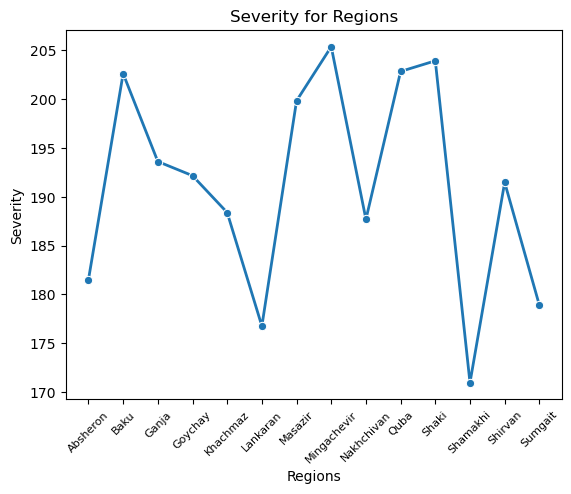

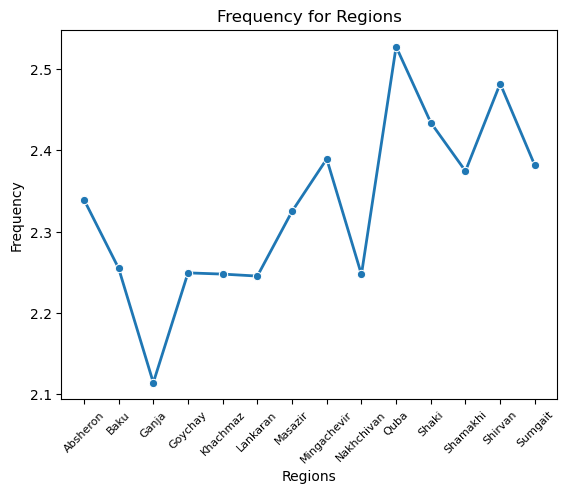

In [6]:
#6
total_approved_region=mergeddf.groupby('region')['approved_amount'].sum()
claim_count_region=mergeddf.groupby('region')['claim_id'].count()
policy_count_region=mergeddf.groupby('region')['policy_id'].nunique()
region_summary=pd.DataFrame({
    'claim_severity':total_approved_region/claim_count_region,
    'claim_frequency':claim_count_region/policy_count_region }).reset_index()
print(region_summary)

import seaborn as sns
import matplotlib.pyplot as plt
sns.lineplot(
    data=region_summary,
    x="region",
    y="claim_severity",
    marker="o",
    linewidth=2
)
plt.xticks(rotation=45,fontsize=8)
plt.title("Severity for Regions")
plt.xlabel("Regions")
plt.ylabel("Severity")
plt.show()   

sns.lineplot(
    data=region_summary,
    x="region",
    y="claim_frequency",
    marker="o",
    linewidth=2
)
plt.xticks(rotation=45,fontsize=8)
plt.title("Frequency for Regions")
plt.xlabel("Regions")
plt.ylabel("Frequency")
plt.show()

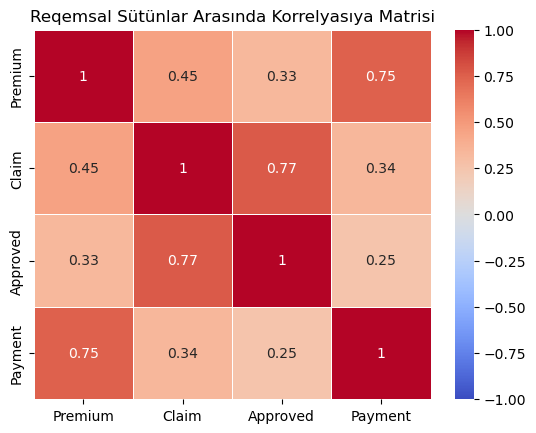

In [7]:
#7
import seaborn as sns
import matplotlib.pyplot as plt
Reqemsal=['premium_amount','claim_amount','approved_amount','payment_amount']
corr_reqemsal=mergeddf[Reqemsal].corr()
lebels=['Premium','Claim','Approved','Payment']
sns.heatmap(
    corr_reqemsal,
    annot=True,
    cmap='coolwarm',
    linewidths=0.5,
    vmin=-1, vmax=1,
    xticklabels=lebels,
    yticklabels=lebels
)
plt.title('Reqemsal Sütünlar Arasında Korrelyasıya Matrisi',fontsize=12)
plt.show()

In [13]:
#8
claim_count_id=mergeddf.groupby('customer_id')['claim_id'].nunique()
policy_count_id=mergeddf.groupby('customer_id')['policy_id'].nunique()
df_risk['claim_frequency_id']=df_risk['claim_count']/policy_count_id
def assign_risk(row):
    if row['loss_ratio'] >0.8 or row['claim_frequency_id']>1:
        return 'Yuksek Risk'
    elif row['loss_ratio'] >0.3 or row['claim_frequency_id']>=0.5:
        return 'Orta Risk'
    else:
        return 'Asagi Risk'
df_risk['risk_levell']=df_risk.apply(assign_risk,axis=1)
print(df_risk.head(20))

             loss_ratio  claim_count  claim_frequency_id  risk_levell
customer_id                                                          
1              0.301585           24            4.000000  Yuksek Risk
2              0.279367            4            1.333333  Yuksek Risk
3              0.067755            8            2.000000  Yuksek Risk
4              0.132154           23            3.833333  Yuksek Risk
5              0.079217           14            1.555556  Yuksek Risk
6              0.044868           10            3.333333  Yuksek Risk
7              0.231413           12            2.400000  Yuksek Risk
8              0.459083           20            2.857143  Yuksek Risk
9              0.454538           10            2.500000  Yuksek Risk
10             0.316273           11            5.500000  Yuksek Risk
11             0.484432            5            1.666667  Yuksek Risk
12             0.207776            9            3.000000  Yuksek Risk
13             0.216